In [1]:
import numpy as np
import pandas as pd
from part2 import RaceSimulator, plot_tires, find_best_strategy

In [2]:
# create simulator object
sim = RaceSimulator()
sim.tires

,Tmin,Tmax,alpha,beta
Soft,0,10,0.5000,15
Medium,1,10,0.2500,25
Hard,2,10,0.0625,55


In [3]:
# total time added from excel sheet
total_time_excel = pd.read_excel('Assignment 3a.xlsx', header=None).iloc[17,0]
print('Total race time added:', round(total_time_excel, 2))

Total race time added: 175.12


Graph for tire degredation:


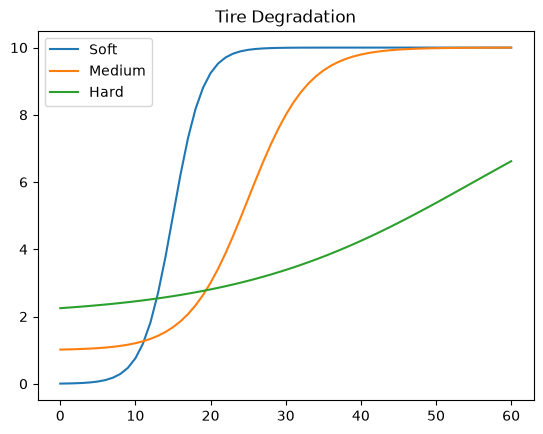

In [4]:
print('Graph for tire degredation:')
plot_tires(sim)

In [5]:
# Normal Cases
# Valid strategies add up to 60 laps, uses at least 2 different tire types, proper tire names

# normla test 1: strategy from excel sheet with pit stops at lap 15 and 23. Soft, medium, hard tire types
stint_lengths = (14, 8, 38)
tire_types = ('Soft', 'Medium', 'Hard')
expected = total_time_excel
actual = sim.simulate(stint_lengths, tire_types)

print('Input:', stint_lengths, tire_types)
print('Expected:', round(expected, 4))
print('Actual:', round(actual, 4))

assert actual == expected
print('Test 1: Passed')

Input: (14, 8, 38) ('Soft', 'Medium', 'Hard')
Expected: 175.1203
Actual: 175.1203
Test 1: Passed


In [6]:
# normal test 2: medium, medium, hard with stints 20, 20, 20

stint_lengths = (20, 20, 20)
tire_types = ('Medium', 'Medium', 'Hard')

medium, hard = sim.tires.loc['Medium'], sim.tires.loc['Hard']

expected = (np.sum(sim.tire_time(np.arange(20), medium['Tmin'], medium['Tmax'], medium['alpha'], medium['beta']))
            + np.sum(sim.tire_time(np.arange(20), medium['Tmin'], medium['Tmax'], medium['alpha'], medium['beta']))
            + np.sum(sim.tire_time(np.arange(20), hard['Tmin'], hard['Tmax'], hard['alpha'], hard['beta']))
            + (2 * 25))
actual = sim.simulate(stint_lengths, tire_types)

print('Input:', stint_lengths, tire_types)
print('Expected:', round(expected, 4))
print('Actual:', round(actual, 4))

assert actual == expected
print('Test 2: Passed')

Input: (20, 20, 20) ('Medium', 'Medium', 'Hard')
Expected: 155.3622
Actual: 155.3622
Test 2: Passed


In [7]:
# Special test 1: shortest possible stints (1 lap each) for stints 1 and 2

stint_lengths = (1, 1, 58)
tire_types = ('Soft', 'Medium', 'Hard')
soft, medium, hard = sim.tires.loc['Soft'], sim.tires.loc['Medium'], sim.tires.loc['Hard']

expected = (np.sum(sim.tire_time(np.arange(1), soft['Tmin'], soft['Tmax'], soft['alpha'], soft['beta']))
            + np.sum(sim.tire_time(np.arange(1), medium['Tmin'], medium['Tmax'], medium['alpha'], medium['beta']))
            + np.sum(sim.tire_time(np.arange(58), hard['Tmin'], hard['Tmax'], hard['alpha'], hard['beta']))
            + (2 * 25))
actual = sim.simulate(stint_lengths, tire_types)

print('Input:', stint_lengths, tire_types)
print('Expected:', round(expected, 4))
print('Actual:', round(actual, 4))

assert actual == expected
print('Special Test 1: Passed - one lap stints')

Input: (1, 1, 58) ('Soft', 'Medium', 'Hard')
Expected: 262.2043
Actual: 262.2043
Special Test 1: Passed - one lap stints


In [8]:
# Special test 2: the same tire used in non-adjacent stints (Soft, Hard, Soft)

stint_lengths = (10, 30, 20)
tire_types = ('Soft', 'Hard', 'Soft')

expected = (np.sum(sim.tire_time(np.arange(10), soft['Tmin'], soft['Tmax'], soft['alpha'], soft['beta']))
            + np.sum(sim.tire_time(np.arange(30), hard['Tmin'], hard['Tmax'], hard['alpha'], hard['beta']))
            + np.sum(sim.tire_time(np.arange(20), soft['Tmin'], soft['Tmax'], soft['alpha'], soft['beta']))
            + (2 * 25))
actual = sim.simulate(stint_lengths, tire_types)

print('Input:', stint_lengths, tire_types)
print('Expected:', round(expected, 4))
print('Actual:', round(actual, 4))

assert actual == expected
print('Special Test 1: Passed - repeated tire')

Input: (10, 30, 20) ('Soft', 'Hard', 'Soft')
Expected: 177.9414
Actual: 177.9414
Special Test 1: Passed - repeated tire


In [9]:
# Error case 1: laps add up to 61 instead of 60
stint_lengths = (14, 8, 39)
tire_types = ('Soft', 'Medum', 'Hard')

print('Input:', stint_lengths, tire_types)
print('Expected: ValueError')

try:
    sim.simulate(stint_lengths, tire_types)
    raised = False
except ValueError as e:
    raised = True
    print('Actual: ValueError,', e)

assert raised
print('Error Test 1: Passed - invalid lap total')

Input: (14, 8, 39) ('Soft', 'Medum', 'Hard')
Expected: ValueError
Actual: ValueError, Stint lengths must add up to 60 total laps.
Error Test 1: Passed - invalid lap total


In [10]:
# Error case 2: only one tire type used for all 3 stints

stint_lengths = (20, 20, 20)
tire_types = ('Soft', 'Soft', 'Soft')

print('Input:', stint_lengths, tire_types)
print('Expected: ValueError')

try:
    sim.simulate(stint_lengths, tire_types)
    raised = False
except ValueError as e:
    raised = True
    print('Actual: ValueError,', e)

assert raised
print('Error Test 2: Passed - must use at least 2 different tires')

Input: (20, 20, 20) ('Soft', 'Soft', 'Soft')
Expected: ValueError
Actual: ValueError, Minimum two tire types must be used.
Error Test 2: Passed - must use at least 2 different tires


In [11]:
# find best strategy
best = find_best_strategy(sim)
best

{'pit_laps': (23, 46),
 'stint_lengths': (22, 23, 15),
 'tire_types': ('Medium', 'Medium', 'Soft'),
 'total_time': 134.2730167184821}

In [12]:
print('Best strategy:', best)

# check strategy is valid
assert len(best['stint_lengths']) == 3
assert sum(best['stint_lengths']) == 60
assert len(set(best['tire_types'])) >= 2
print('Passed: strategy follows race rules')

# check total time using simulate()
check = sim.simulate(best['stint_lengths'], best['tire_types'])
print(f'Expected: {check:.4f}')
print(f'Actual: {best['total_time']:.4f}')
assert check == best['total_time']
print('Passed: simulate() gives same total')

Best strategy: {'pit_laps': (23, 46), 'stint_lengths': (22, 23, 15), 'tire_types': ('Medium', 'Medium', 'Soft'), 'total_time': 134.2730167184821}
Passed: strategy follows race rules
Expected: 134.2730
Actual: 134.2730
Passed: simulate() gives same total
